# Titanic Data Analysis with Pandas
### Data Understanding, Preparation, and Passenger Survival Analysis



# 1) Project Brief

The objective is to understand which passenger characteristics are associated with survival in the supplied Titanic sample. We examine sex, passenger class, age, fare, embarkation port, recorded family members, cabin information, and shared tickets.

This is exploratory analysis, not a machine-learning prediction project. The outcome is `Survived`: **0 = did not survive**, **1 = survived**. All findings describe this sample of passengers.

## 1.1) Import Libraries


In [21]:
# %pip install pandas numpy matplotlib seaborn

In [22]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## 1.2) Load the Dataset


In [23]:
df_raw = pd.read_csv("titanic_dataset.csv")
df = df_raw.copy()
df.shape

(891, 12)

#####`df_raw` is the original source; `df` is used for inspection.

# 2) Data Understanding

### Column Dictionary

| Column | Meaning | Analytical role |
|---|---|---|
| PassengerId | Passenger identifier | Identifier |
| Survived | 0 = did not survive; 1 = survived | Binary outcome |
| Pclass | 1 = first; 2 = second; 3 = third class | Ordered category |
| Name | Passenger full name | Text; can provide a title |
| Sex | Recorded male/female category | Category |
| Age | Age in years | Numerical; fractional ages represent infants |
| SibSp | Siblings or spouses aboard | Numerical count |
| Parch | Parents or children aboard | Numerical count |
| Ticket | Ticket identifier | Identifier; useful for shared-ticket analysis |
| Fare | Recorded ticket fare | Numerical |
| Cabin | Recorded cabin number(s) | Text with substantial missingness |
| Embarked | C = Cherbourg; Q = Queenstown; S = Southampton | Category |

Each row represents **one passenger**, not one ticket or one family. Several passengers may share a ticket.

## 2.1) First Records


In [24]:
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


## 2.2) Last Records




In [25]:
df.tail()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.00,NaN,S
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.00,B42,S
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.45,NaN,S
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.00,C148,C
890,891,0,3,"Dooley, Mr. Patrick",male,32.0,0,0,370376,7.75,NaN,Q


## 2.3) Random Sample


In [26]:
df.sample(5, random_state=42)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
709,710,1,3,"Moubarek, Master. Halim Gonios (""William George"")",male,NaN,1,1,2661,15.2458,NaN,C
439,440,0,2,"Kvillner, Mr. Johan Henrik Johannesson",male,31.0,0,0,C.A. 18723,10.5000,NaN,S
840,841,0,3,"Alhomaki, Mr. Ilmari Rudolf",male,20.0,0,0,SOTON/O2 3101287,7.9250,NaN,S
720,721,1,2,"Harper, Miss. Annie Jessie ""Nina""",female,6.0,0,1,248727,33.0000,NaN,S
39,40,1,3,"Nicola-Yarred, Miss. Jamila",female,14.0,1,0,2651,11.2417,NaN,C


## 2.4) Confirm the Data Grain

**Objective:** Distinguish passenger counts from ticket counts.

In [27]:
print("Passenger rows:", len(df))
print("Unique passenger IDs:", df["PassengerId"].nunique())
print("Unique tickets:", df["Ticket"].nunique())

Passenger rows: 891
Unique passenger IDs: 891
Unique tickets: 681


## 2.5) Shape and Column Names

**Objective:** Confirm the exact field names.

In [28]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
df.columns

Rows: 891
Columns: 12


Index(['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp',
       'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked'],
      dtype='str')

## 2.6) Data Types and Non-null Counts

**Objective:** Review storage types and missingness.

In [29]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


### Interpretation

Age and Fare are floating-point numerical fields. Name, Sex, Ticket, Cabin and Embarked are text fields. Survived and Pclass are stored as integers but represent categories.

## 2.7) Numerical Statistics

**Objective:** Summarize numerical variables with meaningful analytical roles.

In [30]:
df[["Age", "Fare", "SibSp", "Parch"]].describe().T

,count,mean,std,min,25%,50%,75%,max
Age,714.0,29.699118,14.526497,0.42,20.1250,28.0000,38.0,80.0000
Fare,891.0,32.204208,49.693429,0.00,7.9104,14.4542,31.0,512.3292
SibSp,891.0,0.523008,1.102743,0.00,0.0000,0.0000,1.0,8.0000
Parch,891.0,0.381594,0.806057,0.00,0.0000,0.0000,0.0,6.0000


### Interpretation

Age is available for 714 passengers. Fare has a mean of 32.20 and a median of 14.45, indicating a right-skewed distribution. The maximum fare of 512.33 needs context rather than automatic removal.

## 2.8) Categorical Statistics

**Objective:** Summarize text categories and inspect their cardinality.

In [31]:
categorical_cols = ["Sex", "Embarked", "Pclass", "Survived"]

for col in categorical_cols:
    print("\nColumn:", col)
    print("Unique values:", df[col].unique())
    print(df[col].value_counts(dropna=False))


Column: Sex
Unique values: <StringArray>
['male', 'female']
Length: 2, dtype: str
Sex
male      577
female    314
Name: count, dtype: int64

Column: Embarked
Unique values: <StringArray>
['S', 'C', 'Q', nan]
Length: 4, dtype: str
Embarked
S      644
C      168
Q       77
NaN      2
Name: count, dtype: int64

Column: Pclass
Unique values: [3 1 2]
Pclass
3    491
1    216
2    184
Name: count, dtype: int64

Column: Survived
Unique values: [0 1]
Survived
0    549
1    342
Name: count, dtype: int64


### Interpretation

The sample contains 577 males and 314 females. Third class has 491 passengers, the largest class. Southampton is the most common known embarkation port (644 passengers). The two missing ports are shown explicitly.

# 3) Data Quality Assessment

## 3.1) Missing Values

**Objective:** Measure both the count and percentage of missing values.

In [32]:
missing_summary = pd.DataFrame({
    "Missing_Count": df.isna().sum(),
    "Missing_Pct": df.isna().mean() * 100
}).sort_values("Missing_Pct", ascending=False)

missing_summary

,Missing_Count,Missing_Pct
Cabin,687,77.104377
Age,177,19.865320
Embarked,2,0.224467
PassengerId,0,0.000000
Name,0,0.000000
Pclass,0,0.000000
Survived,0,0.000000
Sex,0,0.000000
Parch,0,0.000000
SibSp,0,0.000000


### Interpretation

Cabin is missing for 687 passengers (77.10%), Age for 177 (19.87%), and Embarked for 2 (0.22%). A blanket `dropna()` would remove many valid passengers and distort the analysis.

## 3.2) Exact and Passenger-key Duplicates

**Objective:** Check repeated records and repeated passenger identities.

In [33]:
print("Exact duplicate rows:", df.duplicated().sum())
print("Duplicate PassengerId values:", df.duplicated(subset=["PassengerId"]).sum())

Exact duplicate rows: 0
Duplicate PassengerId values: 0


## 3.3) Invalid Categories and Ranges

**Objective:** Check whether coded categories or numerical values violate basic rules.

In [34]:
validation = pd.Series({
    "Invalid Survived": (~df["Survived"].isin([0, 1])).sum(),
    "Invalid Pclass": (~df["Pclass"].isin([1, 2, 3])).sum(),
    "Invalid Sex": (~df["Sex"].isin(["male", "female"])).sum(),
    "Invalid known Embarked": (~df["Embarked"].dropna().isin(["C", "Q", "S"])).sum(),
    "Age outside 0 to 120": ((df["Age"] < 0) | (df["Age"] > 120)).sum(),
    "Negative Fare": (df["Fare"] < 0).sum(),
    "Negative SibSp": (df["SibSp"] < 0).sum(),
    "Negative Parch": (df["Parch"] < 0).sum(),
    "Non-integer SibSp": (df["SibSp"] % 1 != 0).sum(),
    "Non-integer Parch": (df["Parch"] % 1 != 0).sum()
})

validation

Invalid Survived          0
Invalid Pclass            0
Invalid Sex               0
Invalid known Embarked    0
Age outside 0 to 120      0
Negative Fare             0
Negative SibSp            0
Negative Parch            0
Non-integer SibSp         0
Non-integer Parch         0
dtype: int64

## 3.4) Statistical Outlier Review

**Objective:** Flag unusual Age, Fare, SibSp and Parch values without deleting them.

In [35]:
outlier_rows = []

for col in ["Age", "Fare", "SibSp", "Parch"]:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    lower_limit = q1 - 1.5 * iqr
    upper_limit = q3 + 1.5 * iqr
    flagged = df[(df[col] < lower_limit) | (df[col] > upper_limit)]

    outlier_rows.append({
        "Column": col,
        "Minimum": df[col].min(),
        "Maximum": df[col].max(),
        "Lower_Limit": lower_limit,
        "Upper_Limit": upper_limit,
        "Flagged_Rows": len(flagged)
    })

pd.DataFrame(outlier_rows)

,Column,Minimum,Maximum,Lower_Limit,Upper_Limit,Flagged_Rows
0,Age,0.42,80.0000,-6.6875,64.8125,11
1,Fare,0.00,512.3292,-26.7240,65.6344,116
2,SibSp,0.00,8.0000,-1.5000,2.5000,46
3,Parch,0.00,6.0000,0.0000,0.0000,213


### Code Explanation

`quantile(0.25)` and `quantile(0.75)` define the central 50% of values. IQR is their difference. The 1.5×IQR bounds are statistical flags, not proof of incorrect data.

### Interpretation

The IQR rule flags 11 ages, 116 fares, 46 SibSp values and 213 Parch values. Count variables can have zero IQR because most observations are zero, so their flags are especially unsuitable as deletion rules. All plausible records remain.

## 3.5) Inspect Extreme Fares

**Objective:** See the highest recorded fares with class and ticket context.

In [36]:
df.nlargest(5, "Fare")[[
    "PassengerId", "Name", "Pclass", "Ticket", "Fare", "Survived"
]]

,PassengerId,Name,Pclass,Ticket,Fare,Survived
258,259,"Ward, Miss. Anna",1,PC 17755,512.3292,1
679,680,"Cardeza, Mr. Thomas Drake Martinez",1,PC 17755,512.3292,1
737,738,"Lesurer, Mr. Gustave J",1,PC 17755,512.3292,1
27,28,"Fortune, Mr. Charles Alexander",1,19950,263.0000,0
88,89,"Fortune, Miss. Mabel Helen",1,19950,263.0000,1


### Interpretation

High fares occur in first class, and identical fares can occur for passengers sharing a ticket. This supports retaining them while interpreting Fare cautiously.

# 4) Data Preparation and Feature Engineering

### Preparation Decisions

| Field / issue | Decision | Reason |
|---|---|---|
| Raw data | Preserve `df_raw` | Keep the source available for comparison |
| Age | Retain missing values | Avoid inventing ages for age-specific findings |
| Embarked | Label missing values Unknown | Keep passengers without guessing a port |
| Cabin | Retain text and create availability indicator | Missingness is extensive and informative |
| Outliers | Retain plausible values | Extreme fares and family counts need not be errors |
| PassengerId / Ticket / Name | Retain, but exclude identifiers from correlation | Identifier numbers are not meaningful continuous measures |

No rows are dropped from the main dataset. A separate `df_age` contains only passengers with recorded ages for age-specific comparisons.

## 4.1) Create the Prepared Copy

**Objective:** Apply the justified missing-port treatment.

In [37]:
df_clean = df.copy()
df_clean["Embarked"] = df_clean["Embarked"].fillna("Unknown")

print("Rows after preparation:", len(df_clean))
print("Missing ages retained:", df_clean["Age"].isna().sum())

Rows after preparation: 891
Missing ages retained: 177


### Interpretation

All 891 passengers remain. The two unknown ports receive a label for grouped reporting, while the 177 unknown ages remain missing.

## 4.2) Readable Outcome and Class Labels

**Objective:** Map coded fields to readable labels without replacing the originals.

In [38]:
survival_map = {0: "Did Not Survive", 1: "Survived"}
class_map = {1: "First", 2: "Second", 3: "Third"}

df_clean["Survival_Status"] = df_clean["Survived"].map(survival_map)
df_clean["Class_Name"] = df_clean["Pclass"].map(class_map)

df_clean[["Survived", "Survival_Status", "Pclass", "Class_Name"]].head()

,Survived,Survival_Status,Pclass,Class_Name
0,0,Did Not Survive,3,Third
1,1,Survived,1,First
2,1,Survived,3,Third
3,1,Survived,1,First
4,0,Did Not Survive,3,Third


### Interpretation

`map()` translates values using a dictionary, as in the reference notebook. Keeping the original Survived column lets us calculate survival rates from 0/1 values.

## 4.3) Family Size and Alone Status

**Objective:** Measure recorded relatives and identify passengers without them.

In [39]:
df_clean["FamilySize"] = df_clean["SibSp"] + df_clean["Parch"] + 1

df_clean["Travel_Group"] = "With recorded family"
df_clean.loc[df_clean["FamilySize"] == 1, "Travel_Group"] = "Alone"

df_clean[["SibSp", "Parch", "FamilySize", "Travel_Group"]].head()

,SibSp,Parch,FamilySize,Travel_Group
0,1,0,2,With recorded family
1,1,0,2,With recorded family
2,0,0,1,Alone
3,1,0,2,With recorded family
4,0,0,1,Alone


## 4.4) Age Groups and Children

**Objective:** Define age bins and a documented child threshold.

In [40]:
age_bins = [0, 16, 30, 45, 60, np.inf]
age_labels = ["0-15", "16-29", "30-44", "45-59", "60+"]

df_clean["AgeGroup"] = pd.cut(
    df_clean["Age"], bins=age_bins, labels=age_labels, right=False
)

df_clean["Age_Category"] = "Unknown"
df_clean.loc[df_clean["Age"] < 16, "Age_Category"] = "Child (<16)"
df_clean.loc[df_clean["Age"] >= 16, "Age_Category"] = "Adult (16+)"

df_age = df_clean.dropna(subset=["Age"]).copy()

print("Passengers with recorded ages:", len(df_age))
print(df_clean["Age_Category"].value_counts())

Passengers with recorded ages: 714
Age_Category
Adult (16+)    631
Unknown        177
Child (<16)     83
Name: count, dtype: int64


In [41]:
df_clean

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,Survival_Status,Class_Name,FamilySize,Travel_Group,AgeGroup,Age_Category
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S,Did Not Survive,Third,2,With recorded family,16-29,Adult (16+)
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C,Survived,First,2,With recorded family,30-44,Adult (16+)
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S,Survived,Third,1,Alone,16-29,Adult (16+)
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S,Survived,First,2,With recorded family,30-44,Adult (16+)
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S,Did Not Survive,Third,1,Alone,30-44,Adult (16+)
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.0000,NaN,S,Did Not Survive,Second,1,Alone,16-29,Adult (16+)
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.0000,B42,S,Survived,First,1,Alone,16-29,Adult (16+)
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.4500,NaN,S,Did Not Survive,Third,4,With recorded family,NaN,Unknown
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.0000,C148,C,Survived,First,1,Alone,16-29,Adult (16+)


### Interpretation

There are 83 children under 16, 631 adults with known ages, and 177 passengers with unknown ages. The 714-row `df_age` is used only for age-specific summaries.

## 4.5) Fare Quartiles

**Objective:** Create sample-relative fare groups for rate comparison.

In [42]:
fare_labels = ["Q1 Lowest", "Q2", "Q3", "Q4 Highest"]

df_clean["FareGroup"] = pd.qcut(
    df_clean["Fare"], q=4, labels=fare_labels
)

print("Fare quartile boundaries:")
print(df_clean["Fare"].quantile([0, 0.25, 0.50, 0.75, 1]))
print("\nPassengers per group:")
print(df_clean["FareGroup"].value_counts(sort=False))

Fare quartile boundaries:
0.00      0.0000
0.25      7.9104
0.50     14.4542
0.75     31.0000
1.00    512.3292
Name: Fare, dtype: float64

Passengers per group:
FareGroup
Q1 Lowest     223
Q2            224
Q3            222
Q4 Highest    222
Name: count, dtype: int64


### Code Explanation

`cut()` uses chosen numerical intervals; `qcut()` uses sample quantiles to form groups of approximately equal size. Q4 is the highest quarter of recorded fares in this sample, not an official ticket category.

### Interpretation

The boundaries are approximately 0, 7.91, 14.45, 31.00 and 512.33. Equal fares at a boundary can produce slightly unequal group sizes.

## 4.6) Cabin Information

**Objective:** Create a simple recorded-cabin indicator.

In [43]:
df_clean["Cabin_Info"] = df_clean["Cabin"].notna().map({
    True: "Available", False: "Missing"
})

df_clean["Cabin_Info"].value_counts()

Cabin_Info
Missing      687
Available    204
Name: count, dtype: int64

### Interpretation

Cabin information is available for 204 passengers and missing for 687. Missing text does not mean the passenger had no cabin.

## 4.7) Shared Tickets

**Objective:** Count ticket occurrences and attach the count using a left merge.

In [44]:
ticket_counts = (
    df_clean.groupby("Ticket", as_index=False)
    .agg(TicketGroupSize=("PassengerId", "size"))
)

df_clean = df_clean.merge(
    ticket_counts, on="Ticket", how="left", validate="many_to_one"
)

df_clean["Ticket_Type"] = "Unique ticket"
df_clean.loc[df_clean["TicketGroupSize"] > 1, "Ticket_Type"] = "Shared ticket"

df_clean[["Ticket", "TicketGroupSize", "Ticket_Type"]].head()

,Ticket,TicketGroupSize,Ticket_Type
0,A/5 21171,1,Unique ticket
1,PC 17599,1,Unique ticket
2,STON/O2. 3101282,1,Unique ticket
3,113803,2,Shared ticket
4,373450,1,Unique ticket


### Code Explanation

`groupby()` builds a ticket-level lookup. `merge(..., how="left")` adds it to the passenger-level table. `validate="many_to_one"` checks that each ticket has only one lookup row, preventing accidental row multiplication.

### Interpretation

The left merge retains passenger rows and adds one count per ticket. A shared ticket occurs more than once in this dataset. The sample does not necessarily include everyone who used that ticket.

## 4.8) Name Titles — Optional Advanced Feature

**Objective:** Extract the title using readable string splitting.

In [45]:
df_clean["Title"] = (
    df_clean["Name"].str.split(",").str[1]
    .str.split(".").str[0].str.strip()
)

df_clean[["Name", "Title"]].head()

,Name,Title
0,"Braund, Mr. Owen Harris",Mr
1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",Mrs
2,"Heikkinen, Miss. Laina",Miss
3,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",Mrs
4,"Allen, Mr. William Henry",Mr


### Interpretation

In names formatted as `Surname, Title. Given name`, the text after the comma and before the first period is the title. This avoids a regular-expression requirement and is adequate for these supplied names. Titles overlap with sex, age and social characteristics.

## 4.9) Validate Preparation

**Objective:** Confirm that feature creation retained the source measurements.

In [46]:
print("Raw passengers:", len(df_raw))
print("Prepared passengers:", len(df_clean))
print("Duplicate passenger IDs:", df_clean["PassengerId"].duplicated().sum())
print("Missing Ages:", df_clean["Age"].isna().sum())
print("Missing Cabins:", df_clean["Cabin"].isna().sum())
print("Total survivors:", df_clean["Survived"].sum())

df_clean.head()

Raw passengers: 891
Prepared passengers: 891
Duplicate passenger IDs: 0
Missing Ages: 177
Missing Cabins: 687
Total survivors: 342


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,...,Class_Name,FamilySize,Travel_Group,AgeGroup,Age_Category,FareGroup,Cabin_Info,TicketGroupSize,Ticket_Type,Title
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,...,Third,2,With recorded family,16-29,Adult (16+),Q1 Lowest,Missing,1,Unique ticket,Mr
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,...,First,2,With recorded family,30-44,Adult (16+),Q4 Highest,Available,1,Unique ticket,Mrs
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,...,Third,1,Alone,16-29,Adult (16+),Q2,Missing,1,Unique ticket,Miss
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,...,First,2,With recorded family,30-44,Adult (16+),Q4 Highest,Available,2,Shared ticket,Mrs
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,...,Third,1,Alone,30-44,Adult (16+),Q2,Missing,1,Unique ticket,Mr


### Interpretation

Preparation retains 891 passengers, 342 survivors, 177 missing ages and 687 missing cabins, with no duplicate passenger IDs. The features support analysis without replacing uncertain measurements.

# 5) Exploratory Data Analysis

Understand the passenger population before comparing survival rates.

## 5.1) Categorical Distributions

**Objective:** Explore outcome, sex, class, family counts and ports separately.

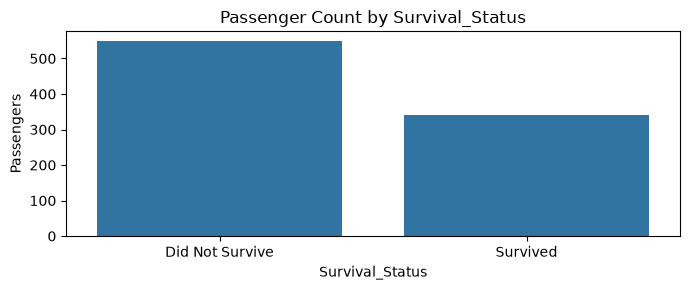

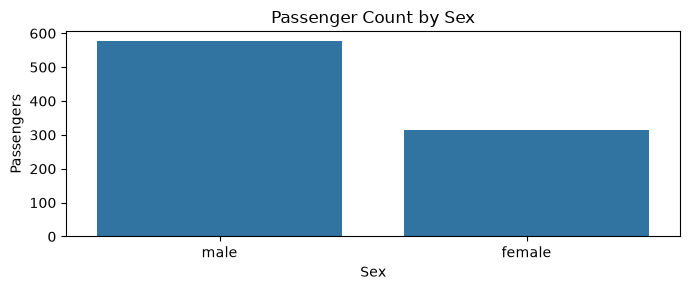

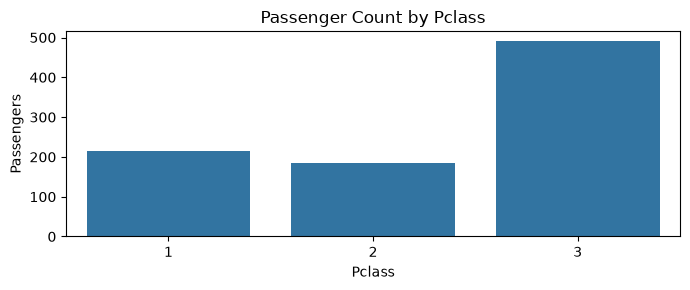

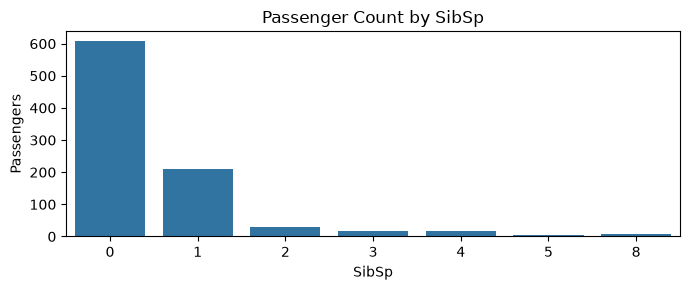

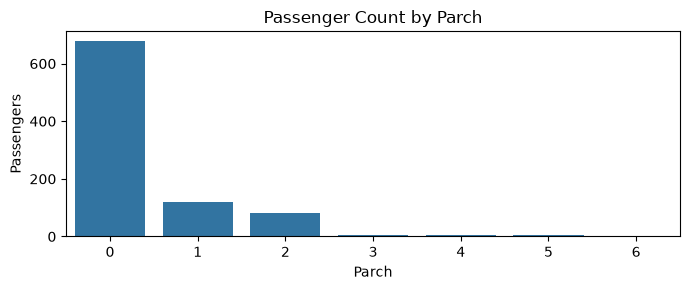

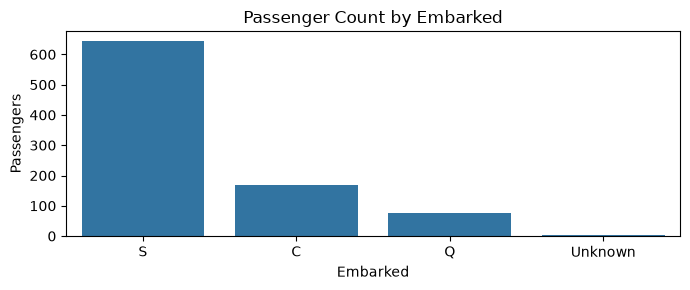

In [47]:
eda_columns = ["Survival_Status", "Sex", "Pclass", "SibSp", "Parch", "Embarked"]

for col in eda_columns:
    plt.figure(figsize=(7, 3))
    sns.countplot(data=df_clean, x=col)
    plt.title("Passenger Count by " + col)
    plt.xlabel(col)
    plt.ylabel("Passengers")
    plt.tight_layout()
    plt.show()

### Interpretation

Non-survivors, males, third-class passengers and Southampton departures form the largest categories. Zero SibSp and zero Parch are common. These are counts of passengers, not survival probabilities.

## 5.2) Age Distribution

**Objective:** Examine the ages that were actually recorded.

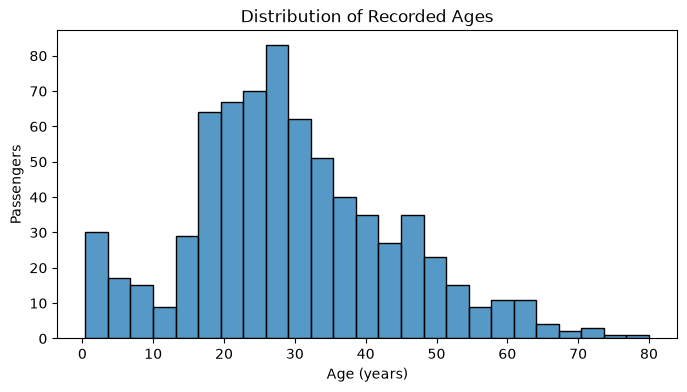

In [48]:
plt.figure(figsize=(8, 4))
sns.histplot(data=df_age, x="Age", bins=25)
plt.title("Distribution of Recorded Ages")
plt.xlabel("Age (years)")
plt.ylabel("Passengers")
plt.show()

### Interpretation

Recorded ages concentrate among young adults. Infants and older passengers are less common. The 177 passengers without ages are excluded from this chart, so it describes the known-age population.

## 5.3) Fare Distribution

**Objective:** Inspect fare skewness and unusual values.

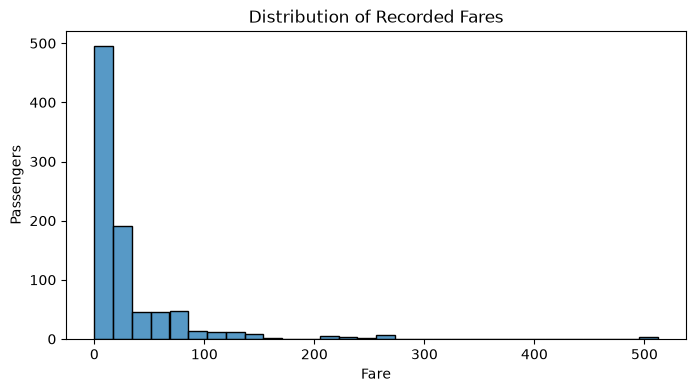

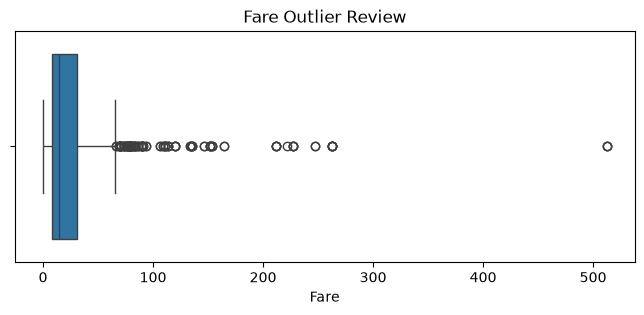

In [49]:
plt.figure(figsize=(8, 4))
sns.histplot(data=df_clean, x="Fare", bins=30)
plt.title("Distribution of Recorded Fares")
plt.xlabel("Fare")
plt.ylabel("Passengers")
plt.show()

plt.figure(figsize=(8, 3))
sns.boxplot(data=df_clean, x="Fare")
plt.title("Fare Outlier Review")
plt.show()

### Interpretation

Most fares are low, while a small number extend far to the right. This supports reporting the median alongside the mean and retaining plausible high values.

## 5.4) Family Travel Overview

**Objective:** Compare passengers alone and with recorded family.

In [50]:
travel_counts = df_clean["Travel_Group"].value_counts().rename("Passengers")
travel_counts

Travel_Group
Alone                   537
With recorded family    354
Name: Passengers, dtype: int64

### Interpretation

There are 537 passengers classified as alone (60.3%) and 354 with recorded family (39.7%). This classification uses SibSp and Parch, not ticket sharing.

# 6) Passenger Survival Analysis — All 30 Questions

### How to Read a Survival Summary

- `Passengers`: number of passenger records in the group.
- `Survivors`: sum of the 0/1 Survived values.
- `Survival_Pct`: mean of Survived multiplied by 100.

For example, values `[1, 0, 1, 0]` have mean 0.5, meaning 50% survival. We show both rates and counts because a high percentage based on two passengers has much less support than a similar percentage based on hundreds.

The code remains explicit in each question so the calculations are visible. For categorical groupings, `observed=True` includes categories present in the data instead of manufacturing empty category combinations. Age analyses use `df_age`, whose 714 passengers have recorded ages.

## Q1) Overall Passenger Survival Rate

**Objective:** Calculate survival for the full sample.

In [95]:
total_passengers = len(df_clean)
total_survivors = df_clean["Survived"].sum()
overall_survival_pct = total_survivors / total_passengers * 100

print("Passengers:", total_passengers)
print("Survivors:", total_survivors)
print("Did not survive:", total_passengers - total_survivors)
print("Survival percentage:", round(overall_survival_pct, 2))

Passengers: 891
Survivors: 342
Did not survive: 549
Survival percentage: 38.38


## Q2) Survival by Sex

**Objective:** Compare male and female passenger outcomes.

In [52]:
survival_by_sex = (
    df_clean.groupby('Sex', as_index=False, observed=True)
    .agg(
        Passengers=("Survived", "size"),
        Survivors=("Survived", "sum"),
        Survival_Rate=("Survived", "mean")
    )
)

survival_by_sex["Survival_Pct"] = survival_by_sex["Survival_Rate"] * 100
survival_by_sex = survival_by_sex.drop(columns=["Survival_Rate"])
survival_by_sex

,Sex,Passengers,Survivors,Survival_Pct
0,female,314,233,74.203822
1,male,577,109,18.890815


### Interpretation

Females survived at **74.20%** (233/314), versus **18.89%** (109/577) for males. This large descriptive association will be checked within passenger classes in Q12.

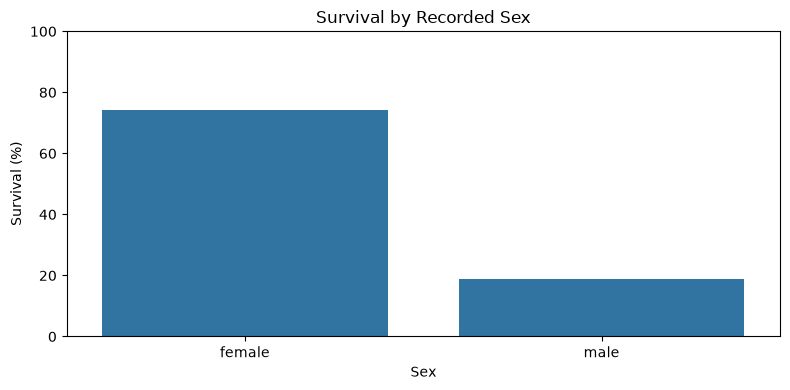

In [53]:
plt.figure(figsize=(8, 4))
sns.barplot(data=survival_by_sex, x="Sex", y="Survival_Pct")
plt.title("Survival by Recorded Sex")
plt.xlabel("Sex")
plt.ylabel("Survival (%)")
plt.ylim(0, 100)
plt.tight_layout()
plt.show()

## Q3) Survival by Passenger Class

**Objective:** Compare the three passenger classes.

In [54]:
survival_by_class = (
    df_clean.groupby('Pclass', as_index=False, observed=True)
    .agg(
        Passengers=("Survived", "size"),
        Survivors=("Survived", "sum"),
        Survival_Rate=("Survived", "mean")
    )
)

survival_by_class["Survival_Pct"] = survival_by_class["Survival_Rate"] * 100
survival_by_class = survival_by_class.drop(columns=["Survival_Rate"])
survival_by_class

,Pclass,Passengers,Survivors,Survival_Pct
0,1,216,136,62.962963
1,2,184,87,47.282609
2,3,491,119,24.236253


### Interpretation

First class had **62.96%** survival (136/216), second class **47.28%** (87/184), and third class **24.24%** (119/491). Survival decreases across class, but the dataset does not identify a causal mechanism.

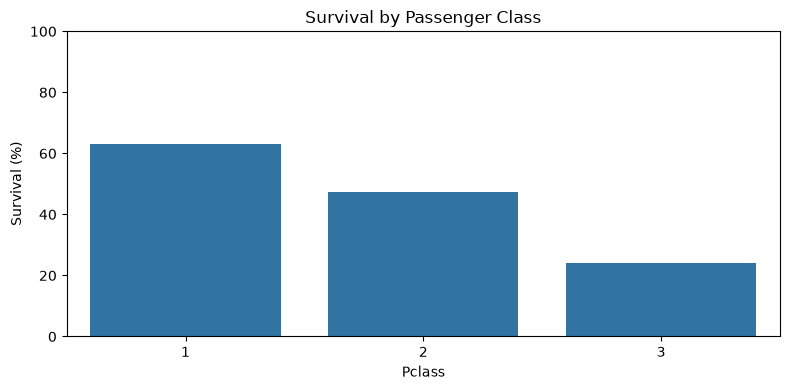

In [55]:
plt.figure(figsize=(8, 4))
sns.barplot(data=survival_by_class, x="Pclass", y="Survival_Pct")
plt.title("Survival by Passenger Class")
plt.xlabel("Pclass")
plt.ylabel("Survival (%)")
plt.ylim(0, 100)
plt.tight_layout()
plt.show()

## Q4) Age and Survival

**Objective:** Compare known-age distributions by outcome.

In [56]:
age_by_outcome = (
    df_age.groupby("Survival_Status")["Age"]
    .agg(["count", "mean", "median", "min", "max"])
)

age_by_outcome

,count,mean,median,min,max
Survival_Status,,,,,
Did Not Survive,424,30.626179,28.0,1.00,74.0
Survived,290,28.343690,28.0,0.42,80.0


### Interpretation

Survivors with known ages averaged **28.34 years**, versus **30.63** for non-survivors. Their distributions overlap substantially; age alone does not explain survival. Missing ages may make this comparison unrepresentative.

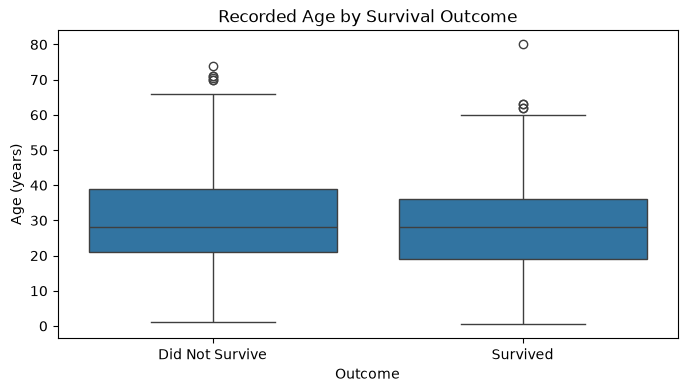

In [57]:
plt.figure(figsize=(8, 4))
sns.boxplot(data=df_age, x="Survival_Status", y="Age")
plt.title("Recorded Age by Survival Outcome")
plt.xlabel("Outcome")
plt.ylabel("Age (years)")
plt.show()

## Q5) Children Compared with Adults

**Objective:** Use the defined under-16 threshold and exclude unknown ages.

In [58]:
survival_by_child_adult = (
    df_age.groupby('Age_Category', as_index=False, observed=True)
    .agg(
        Passengers=("Survived", "size"),
        Survivors=("Survived", "sum"),
        Survival_Rate=("Survived", "mean")
    )
)

survival_by_child_adult["Survival_Pct"] = survival_by_child_adult["Survival_Rate"] * 100
survival_by_child_adult = survival_by_child_adult.drop(columns=["Survival_Rate"])
survival_by_child_adult

,Age_Category,Passengers,Survivors,Survival_Pct
0,Adult (16+),631,241,38.193344
1,Child (<16),83,49,59.036145


### Interpretation

Children had **59.04%** survival (49/83), compared with **38.19%** among known-age adults (241/631). The 177 unknown ages cannot be classified; under 16 is a stated analytical threshold, not a universal definition.

## Q6) Ticket Fare and Survival

**Objective:** Compare fare distributions by outcome.

In [59]:
fare_by_outcome = (
    df_clean.groupby("Survival_Status")["Fare"]
    .agg(["count", "mean", "median", "min", "max"])
)

fare_by_outcome

,count,mean,median,min,max
Survival_Status,,,,,
Did Not Survive,549,22.117887,10.5,0.0,263.0000
Survived,342,48.395408,26.0,0.0,512.3292


### Interpretation

Survivors had higher mean fare (**48.40** versus **22.12**) and median fare (**26.00** versus **10.50**). Fare is also related to class and shared tickets; a higher fare cannot be assumed to cause survival.

## Q7) Embarkation Port and Survival

**Objective:** Compare survival by departure port.

In [60]:
survival_by_port = (
    df_clean.groupby('Embarked', as_index=False, observed=True)
    .agg(
        Passengers=("Survived", "size"),
        Survivors=("Survived", "sum"),
        Survival_Rate=("Survived", "mean")
    )
)

survival_by_port["Survival_Pct"] = survival_by_port["Survival_Rate"] * 100
survival_by_port = survival_by_port.drop(columns=["Survival_Rate"])
survival_by_port

,Embarked,Passengers,Survivors,Survival_Pct
0,C,168,93,55.357143
1,Q,77,30,38.961039
2,S,644,217,33.695652
3,Unknown,2,2,100.000000


### Interpretation

Cherbourg had **55.36%** survival, Queenstown **38.96%**, and Southampton **33.70%**. Unknown has only two passengers, both survivors, so its 100% rate is not reliable evidence of a port effect.

## Q8) Siblings or Spouses Aboard

**Objective:** Examine the number of recorded siblings/spouses.

In [61]:
survival_by_sibsp = (
    df_clean.groupby('SibSp', as_index=False, observed=True)
    .agg(
        Passengers=("Survived", "size"),
        Survivors=("Survived", "sum"),
        Survival_Rate=("Survived", "mean")
    )
)

survival_by_sibsp["Survival_Pct"] = survival_by_sibsp["Survival_Rate"] * 100
survival_by_sibsp = survival_by_sibsp.drop(columns=["Survival_Rate"])
survival_by_sibsp

,SibSp,Passengers,Survivors,Survival_Pct
0,0,608,210,34.539474
1,1,209,112,53.588517
2,2,28,13,46.428571
3,3,16,4,25.000000
4,4,18,3,16.666667
5,5,5,0,0.000000
6,8,7,0,0.000000


### Interpretation

Passengers with one sibling/spouse had **53.59%** survival, versus **34.54%** with none. Large SibSp counts show low survival, but their small samples limit interpretation. The relationship is not a straight linear trend.

## Q9) Parents or Children Aboard

**Objective:** Compare outcomes across Parch counts.

In [62]:
survival_by_parch = (
    df_clean.groupby('Parch', as_index=False, observed=True)
    .agg(
        Passengers=("Survived", "size"),
        Survivors=("Survived", "sum"),
        Survival_Rate=("Survived", "mean")
    )
)

survival_by_parch["Survival_Pct"] = survival_by_parch["Survival_Rate"] * 100
survival_by_parch = survival_by_parch.drop(columns=["Survival_Rate"])
survival_by_parch

,Parch,Passengers,Survivors,Survival_Pct
0,0,678,233,34.365782
1,1,118,65,55.084746
2,2,80,40,50.000000
3,3,5,3,60.000000
4,4,4,0,0.000000
5,5,5,1,20.000000
6,6,1,0,0.000000


### Interpretation

Survival was **34.37%** with no parents/children, **55.08%** with one, and **50.00%** with two. Higher Parch values contain few passengers; extreme percentages in those groups are unstable.

## Q10) Family Size and Survival

**Objective:** Compare survival for the passenger plus recorded relatives.

In [63]:
survival_by_family = (
    df_clean.groupby('FamilySize', as_index=False, observed=True)
    .agg(
        Passengers=("Survived", "size"),
        Survivors=("Survived", "sum"),
        Survival_Rate=("Survived", "mean")
    )
)

survival_by_family["Survival_Pct"] = survival_by_family["Survival_Rate"] * 100
survival_by_family = survival_by_family.drop(columns=["Survival_Rate"])
survival_by_family

,FamilySize,Passengers,Survivors,Survival_Pct
0,1,537,163,30.353818
1,2,161,89,55.279503
2,3,102,59,57.843137
3,4,29,21,72.413793
4,5,15,3,20.000000
5,6,22,3,13.636364
6,7,12,4,33.333333
7,8,6,0,0.000000
8,11,7,0,0.000000


### Interpretation

Family sizes 2–4 show higher survival than lone passengers or large families. The pattern is non-linear, and very large families have few observations.

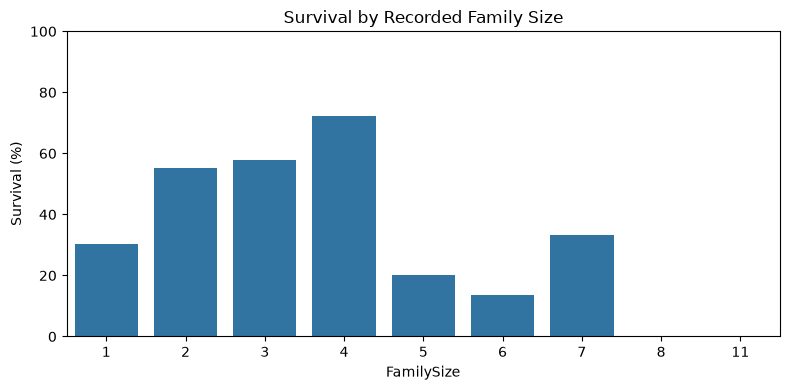

In [64]:
plt.figure(figsize=(8, 4))
sns.barplot(data=survival_by_family, x="FamilySize", y="Survival_Pct")
plt.title("Survival by Recorded Family Size")
plt.xlabel("FamilySize")
plt.ylabel("Survival (%)")
plt.ylim(0, 100)
plt.tight_layout()
plt.show()

## Q11) Alone Compared with Recorded Family

**Objective:** Compare the two travel classifications.

In [65]:
survival_by_travel = (
    df_clean.groupby('Travel_Group', as_index=False, observed=True)
    .agg(
        Passengers=("Survived", "size"),
        Survivors=("Survived", "sum"),
        Survival_Rate=("Survived", "mean")
    )
)

survival_by_travel["Survival_Pct"] = survival_by_travel["Survival_Rate"] * 100
survival_by_travel = survival_by_travel.drop(columns=["Survival_Rate"])
survival_by_travel

,Travel_Group,Passengers,Survivors,Survival_Pct
0,Alone,537,163,30.353818
1,With recorded family,354,179,50.564972


### Interpretation

Passengers with recorded family had **50.56%** survival (179/354), compared with **30.35%** for those classified as alone (163/537). Sex, age and class differences may explain part of this contrast.

## Q12) Sex and Passenger Class Together

**Objective:** Check whether the sex association remains within each class.

In [66]:
survival_by_sex_class = (
    df_clean.groupby(['Sex', 'Pclass'], as_index=False, observed=True)
    .agg(
        Passengers=("Survived", "size"),
        Survivors=("Survived", "sum"),
        Survival_Rate=("Survived", "mean")
    )
)

survival_by_sex_class["Survival_Pct"] = survival_by_sex_class["Survival_Rate"] * 100
survival_by_sex_class = survival_by_sex_class.drop(columns=["Survival_Rate"])
survival_by_sex_class

,Sex,Pclass,Passengers,Survivors,Survival_Pct
0,female,1,94,91,96.808511
1,female,2,76,70,92.105263
2,female,3,144,72,50.000000
3,male,1,122,45,36.885246
4,male,2,108,17,15.740741
5,male,3,347,47,13.544669


### Interpretation

Females have higher survival within every class. Female rates were **96.81%, 92.11%, 50.00%** in first, second and third class; male rates were **36.89%, 15.74%, 13.54%**. Class still matters within sex.

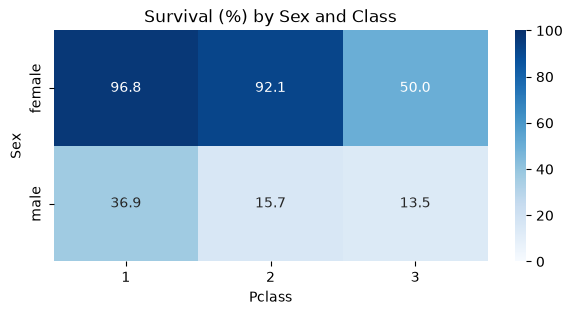

In [67]:
sex_class_pivot = pd.pivot_table(
    df_clean, index="Sex", columns="Pclass", values="Survived",
    aggfunc="mean", observed=True
) * 100

plt.figure(figsize=(7, 3))
sns.heatmap(sex_class_pivot, annot=True, fmt=".1f", cmap="Blues", vmin=0, vmax=100)
plt.title("Survival (%) by Sex and Class")
plt.show()

## Q13) Age across Passenger Classes

**Objective:** Compare ages by class and connect the result with survival.

In [68]:
age_by_class = (
    df_age.groupby("Pclass")["Age"]
    .agg(["count", "mean", "median"])
)

age_by_class

,count,mean,median
Pclass,,,
1,186,38.233441,37.0
2,173,29.877630,29.0
3,355,25.140620,24.0


### Interpretation

First-class passengers were older on average (**38.23**) than second-class (**29.88**) or third-class passengers (**25.14**), yet first class had the highest survival. The class advantage cannot be reduced to younger passengers surviving more.

In [69]:
survival_by_class_age = (
    df_age.groupby(['Pclass', 'AgeGroup'], as_index=False, observed=True)
    .agg(
        Passengers=("Survived", "size"),
        Survivors=("Survived", "sum"),
        Survival_Rate=("Survived", "mean")
    )
)

survival_by_class_age["Survival_Pct"] = survival_by_class_age["Survival_Rate"] * 100
survival_by_class_age = survival_by_class_age.drop(columns=["Survival_Rate"])
survival_by_class_age

,Pclass,AgeGroup,Passengers,Survivors,Survival_Pct
0,1,0-15,6,5,83.333333
1,1,16-29,49,36,73.469388
2,1,30-44,64,49,76.562500
3,1,45-59,50,27,54.000000
4,1,60+,17,5,29.411765
5,2,0-15,19,19,100.000000
6,2,16-29,69,29,42.028986
7,2,30-44,60,26,43.333333
8,2,45-59,21,8,38.095238
9,2,60+,4,1,25.000000


### Interpretation

The class-by-age summary adds the survival evidence for this comparison. Some older strata are small; class, age and sex overlap, so stratification is informative without being a causal adjustment.

## Q14) Fare across Passenger Classes

**Objective:** Compare typical fares and relate them to class survival.

In [70]:
fare_by_class = (
    df_clean.groupby("Pclass")["Fare"]
    .agg(["count", "mean", "median", "min", "max"])
)

fare_by_class

,count,mean,median,min,max
Pclass,,,,,
1,216,84.154687,60.2875,0.0,512.3292
2,184,20.662183,14.2500,0.0,73.5000
3,491,13.675550,8.0500,0.0,69.5500


### Interpretation

First class had median fare **60.29**, second **14.25**, and third **8.05**. First class also had the highest survival in Q3. Fare and class therefore describe overlapping associations.

## Q15) Port and Survival within Class

**Objective:** Investigate class composition behind the port comparison.

In [71]:
survival_by_port_class = (
    df_clean.groupby(['Embarked', 'Pclass'], as_index=False, observed=True)
    .agg(
        Passengers=("Survived", "size"),
        Survivors=("Survived", "sum"),
        Survival_Rate=("Survived", "mean")
    )
)

survival_by_port_class["Survival_Pct"] = survival_by_port_class["Survival_Rate"] * 100
survival_by_port_class = survival_by_port_class.drop(columns=["Survival_Rate"])
survival_by_port_class

,Embarked,Pclass,Passengers,Survivors,Survival_Pct
0,C,1,85,59,69.411765
1,C,2,17,9,52.941176
2,C,3,66,25,37.878788
3,Q,1,2,1,50.000000
4,Q,2,3,2,66.666667
5,Q,3,72,27,37.500000
6,S,1,127,74,58.267717
7,S,2,164,76,46.341463
8,S,3,353,67,18.980170
9,Unknown,1,2,2,100.000000


### Interpretation

Cherbourg has a higher overall rate, but its first-class share is much larger. Within first class, Cherbourg survival is 69.41% versus Southampton 58.27%; small Queenstown/first-class groups are unsuitable for strong claims. Stratification changes the comparison and reduces certainty.

In [72]:
port_class_mix = pd.crosstab(
    df_clean["Embarked"], df_clean["Pclass"], normalize="index"
) * 100

port_class_mix

Pclass,1,2,3
Embarked,,,
C,50.595238,10.119048,39.285714
Q,2.597403,3.896104,93.506494
S,19.720497,25.465839,54.813665
Unknown,100.000000,0.000000,0.000000


### Interpretation

First class accounts for **50.60%** of Cherbourg passengers versus **19.72%** of Southampton passengers. Class composition is a possible explanation for part of the aggregate port difference.

## Q16) Survival across Fare Quartiles

**Objective:** Compare the four sample-relative fare groups.

In [73]:
survival_by_fare_group = (
    df_clean.groupby('FareGroup', as_index=False, observed=True)
    .agg(
        Passengers=("Survived", "size"),
        Survivors=("Survived", "sum"),
        Survival_Rate=("Survived", "mean")
    )
)

survival_by_fare_group["Survival_Pct"] = survival_by_fare_group["Survival_Rate"] * 100
survival_by_fare_group = survival_by_fare_group.drop(columns=["Survival_Rate"])
survival_by_fare_group

,FareGroup,Passengers,Survivors,Survival_Pct
0,Q1 Lowest,223,44,19.730942
1,Q2,224,68,30.357143
2,Q3,222,101,45.495495
3,Q4 Highest,222,129,58.108108


### Interpretation

Survival rates from Q1 to Q4 were **19.73%, 30.36%, 45.50%, 58.11%**. The gradient is clear in this sample but overlaps with class; quartiles are descriptive groupings.

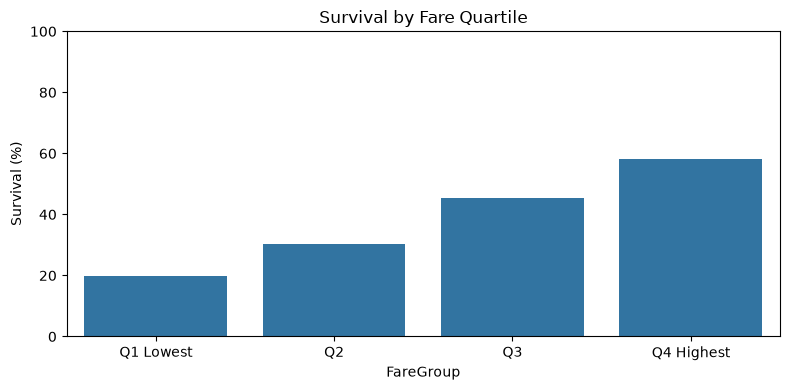

In [74]:
plt.figure(figsize=(8, 4))
sns.barplot(data=survival_by_fare_group, x="FareGroup", y="Survival_Pct")
plt.title("Survival by Fare Quartile")
plt.xlabel("FareGroup")
plt.ylabel("Survival (%)")
plt.ylim(0, 100)
plt.tight_layout()
plt.show()

## Q17) Survival across Age Groups

**Objective:** Compare the defined age intervals using recorded ages.

In [75]:
survival_by_age_group = (
    df_age.groupby('AgeGroup', as_index=False, observed=True)
    .agg(
        Passengers=("Survived", "size"),
        Survivors=("Survived", "sum"),
        Survival_Rate=("Survived", "mean")
    )
)

survival_by_age_group["Survival_Pct"] = survival_by_age_group["Survival_Rate"] * 100
survival_by_age_group = survival_by_age_group.drop(columns=["Survival_Rate"])
survival_by_age_group

,AgeGroup,Passengers,Survivors,Survival_Pct
0,0-15,83,49,59.036145
1,16-29,301,107,35.548173
2,30-44,215,91,42.325581
3,45-59,89,36,40.449438
4,60+,26,7,26.923077


### Interpretation

The under-16 group has the highest observed survival, while ages 60+ have the lowest. Intermediate groups do not form a perfectly decreasing trend. All age-group results exclude the 177 unknown ages.

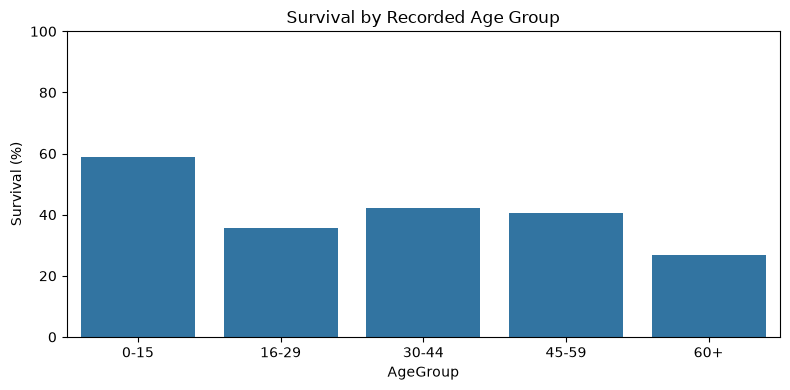

In [76]:
plt.figure(figsize=(8, 4))
sns.barplot(data=survival_by_age_group, x="AgeGroup", y="Survival_Pct")
plt.title("Survival by Recorded Age Group")
plt.xlabel("AgeGroup")
plt.ylabel("Survival (%)")
plt.ylim(0, 100)
plt.tight_layout()
plt.show()

## Q18) Highest and Lowest Sex–Class Combinations

**Objective:** Identify the highest and lowest rates among the six observed groups.

In [77]:
sex_class_ranked = survival_by_sex_class.sort_values("Survival_Pct", ascending=False)

print("Highest survival combination:")
print(sex_class_ranked.head(1).to_string(index=False))
print("\nLowest survival combination:")
print(sex_class_ranked.tail(1).to_string(index=False))

Highest survival combination:
   Sex  Pclass  Passengers  Survivors  Survival_Pct
female       1          94         91     96.808511

Lowest survival combination:
 Sex  Pclass  Passengers  Survivors  Survival_Pct
male       3         347         47     13.544669


### Interpretation

First-class females had the highest rate: **96.81%** (91/94). Third-class males had the lowest: **13.54%** (47/347). These are observed group rates, not certain outcomes for every passenger.

## Q19) Average Fare of Survivors and Non-survivors

**Objective:** Report means with medians for the skewed fare distribution.

In [78]:
df_clean.groupby("Survival_Status")["Fare"].agg(["count", "mean", "median"])

,count,mean,median
Survival_Status,,,
Did Not Survive,549,22.117887,10.5
Survived,342,48.395408,26.0


### Interpretation

Survivors averaged **48.40**, non-survivors **22.12**. Survivors also had the higher median (**26.00** versus **10.50**), so the difference is not confined to the single highest fare.

## Q20) Average Age of Survivors and Non-survivors

**Objective:** Show the number of recorded ages underlying each mean.

In [79]:
df_age.groupby("Survival_Status")["Age"].agg(["count", "mean", "median"])

,count,mean,median
Survival_Status,,,
Did Not Survive,424,30.626179,28.0
Survived,290,28.343690,28.0


### Interpretation

The comparison uses **290** survivors with recorded ages and **424** non-survivors. Means are **28.34** and **30.63**; medians are **28** for both. This is a modest difference rather than a clean separation.

## Q21) Highest and Lowest Age-group Survival

**Objective:** Rank known-age groups using the chosen boundaries.

In [80]:
age_group_ranked = survival_by_age_group.sort_values("Survival_Pct", ascending=False)

print("Highest age-group rate:")
print(age_group_ranked.head(1).to_string(index=False))
print("\nLowest age-group rate:")
print(age_group_ranked.tail(1).to_string(index=False))

Highest age-group rate:
AgeGroup  Passengers  Survivors  Survival_Pct
    0-15          83         49     59.036145

Lowest age-group rate:
AgeGroup  Passengers  Survivors  Survival_Pct
     60+          26          7     26.923077


### Interpretation

Ages under 16 had **59.04%** survival (49/83), while ages 60+ had **26.92%** (7/26). The oldest group is small; rankings may change if age boundaries change.

## Q22) Passenger Class with the Highest Typical Fare

**Objective:** Use the median to define typical fare.

In [81]:
typical_fare_by_class = (
    df_clean.groupby("Pclass", as_index=False)
    .agg(Passengers=("Fare", "size"), Median_Fare=("Fare", "median"))
    .sort_values("Median_Fare", ascending=False)
)

typical_fare_by_class

,Pclass,Passengers,Median_Fare
0,1,216,60.2875
1,2,184,14.2500
2,3,491,8.0500


### Interpretation

First class has the highest typical fare: median **60.29**, compared with **14.25** and **8.05**. Median is preferred for this question because fare is right-skewed.

## Q23) High Fares, First Class and Interpretation

**Objective:** Check which classes contain the highest-fare passengers.

In [82]:
high_fare_passengers = df_clean[df_clean["FareGroup"] == "Q4 Highest"]

high_fare_class_summary = pd.DataFrame({
    "Passengers": high_fare_passengers["Pclass"].value_counts(),
    "Percentage": high_fare_passengers["Pclass"].value_counts(normalize=True) * 100
}).sort_index()

high_fare_class_summary

,Passengers,Percentage
Pclass,,
1,159,71.621622
2,22,9.909910
3,41,18.468468


### Interpretation

First class accounts for **159 of 222** passengers in the highest fare quartile (**71.62%**). A raw fare–survival relationship can partly reflect class composition. The within-class table below shows why these variables should not be interpreted as separate causes.

In [83]:
survival_by_class_fare = (
    df_clean.groupby(['Pclass', 'FareGroup'], as_index=False, observed=True)
    .agg(
        Passengers=("Survived", "size"),
        Survivors=("Survived", "sum"),
        Survival_Rate=("Survived", "mean")
    )
)

survival_by_class_fare["Survival_Pct"] = survival_by_class_fare["Survival_Rate"] * 100
survival_by_class_fare = survival_by_class_fare.drop(columns=["Survival_Rate"])
survival_by_class_fare

,Pclass,FareGroup,Passengers,Survivors,Survival_Pct
0,1,Q1 Lowest,6,0,0.000000
1,1,Q3,51,27,52.941176
2,1,Q4 Highest,159,109,68.553459
3,2,Q1 Lowest,6,0,0.000000
4,2,Q2,86,33,38.372093
5,2,Q3,70,42,60.000000
6,2,Q4 Highest,22,12,54.545455
7,3,Q1 Lowest,211,44,20.853081
8,3,Q2,138,35,25.362319
9,3,Q3,101,32,31.683168


### Interpretation

Fare quartiles are unevenly represented across classes. Some class–fare combinations are small or absent. Within-class comparisons remain descriptive and do not account for every other passenger characteristic.

## Q24) Cabin Information and Survival

**Objective:** Compare passengers with and without recorded cabin text.

In [84]:
survival_by_cabin = (
    df_clean.groupby('Cabin_Info', as_index=False, observed=True)
    .agg(
        Passengers=("Survived", "size"),
        Survivors=("Survived", "sum"),
        Survival_Rate=("Survived", "mean")
    )
)

survival_by_cabin["Survival_Pct"] = survival_by_cabin["Survival_Rate"] * 100
survival_by_cabin = survival_by_cabin.drop(columns=["Survival_Rate"])
survival_by_cabin

,Cabin_Info,Passengers,Survivors,Survival_Pct
0,Available,204,136,66.666667
1,Missing,687,206,29.985444


### Interpretation

Available cabin information is associated with **66.67%** survival (136/204), versus **29.99%** when missing (206/687). Cabin text is missing for 77.10% of passengers, and availability overlaps strongly with class. Do not equate Missing with no cabin.

In [85]:
pd.crosstab(df_clean["Cabin_Info"], df_clean["Pclass"], normalize="index") * 100

Pclass,1,2,3
Cabin_Info,,,
Available,86.274510,7.843137,5.882353
Missing,5.822416,24.454148,69.723435


### Interpretation

The class composition differs sharply between cabin-availability groups. Cabin availability is partly a documentation/class indicator, which limits claims about cabins themselves.

## Q25) Shared versus Unique Tickets

**Objective:** Compare ticket-sharing status within this sample.

In [86]:
survival_by_ticket = (
    df_clean.groupby('Ticket_Type', as_index=False, observed=True)
    .agg(
        Passengers=("Survived", "size"),
        Survivors=("Survived", "sum"),
        Survival_Rate=("Survived", "mean")
    )
)

survival_by_ticket["Survival_Pct"] = survival_by_ticket["Survival_Rate"] * 100
survival_by_ticket = survival_by_ticket.drop(columns=["Survival_Rate"])
survival_by_ticket

,Ticket_Type,Passengers,Survivors,Survival_Pct
0,Shared ticket,344,179,52.034884
1,Unique ticket,547,163,29.798903


### Interpretation

Shared-ticket passengers had **52.03%** survival (179/344), compared with **29.80%** for unique-ticket passengers (163/547). Shared tickets may reflect family or other companions. Counts cover this sample rather than the whole ship, and passengers sharing tickets may have related outcomes.

## Q26) Optional Advanced Analysis: Passenger Titles

**Objective:** Explore titles extracted from the names.

In [87]:
survival_by_title = (
    df_clean.groupby('Title', as_index=False, observed=True)
    .agg(
        Passengers=("Survived", "size"),
        Survivors=("Survived", "sum"),
        Survival_Rate=("Survived", "mean")
    )
)

survival_by_title["Survival_Pct"] = survival_by_title["Survival_Rate"] * 100
survival_by_title = survival_by_title.drop(columns=["Survival_Rate"])
survival_by_title

survival_by_title.sort_values("Passengers", ascending=False)

,Title,Passengers,Survivors,Survival_Pct
11,Mr,517,81,15.667311
8,Miss,182,127,69.780220
12,Mrs,125,99,79.200000
7,Master,40,23,57.500000
3,Dr,7,3,42.857143
14,Rev,6,0,0.000000
9,Mlle,2,2,100.000000
6,Major,2,1,50.000000
1,Col,2,1,50.000000
0,Capt,1,0,0.000000


### Interpretation

Mr is the largest title group and has low survival (**15.67%**). Mrs, Miss and Master show higher rates. Titles partly encode sex, age and social context. One-person titles with 0% or 100% survival do not support reliable generalizations.

## Q27) Correlation Matrix

**Objective:** Explore linear relationships among meaningful numerical fields.

In [88]:
correlation_columns = ["Survived", "Pclass", "Age", "Fare", "SibSp", "Parch", "FamilySize"]

correlation_matrix = df_clean[correlation_columns].corr()
correlation_matrix.round(2)

,Survived,Pclass,Age,Fare,SibSp,Parch,FamilySize
Survived,1.00,-0.34,-0.08,0.26,-0.04,0.08,0.02
Pclass,-0.34,1.00,-0.37,-0.55,0.08,0.02,0.07
Age,-0.08,-0.37,1.00,0.10,-0.31,-0.19,-0.30
Fare,0.26,-0.55,0.10,1.00,0.16,0.22,0.22
SibSp,-0.04,0.08,-0.31,0.16,1.00,0.41,0.89
Parch,0.08,0.02,-0.19,0.22,0.41,1.00,0.78
FamilySize,0.02,0.07,-0.30,0.22,0.89,0.78,1.00


### Interpretation

Survived is negatively correlated with class code (about **-0.34**) and positively with Fare (**0.26**). Age has a weak linear correlation (**-0.08**) despite age-group differences. Class and fare are strongly related (**-0.55**). Sex is excluded because it is text; that does not mean it has a weak association. Pairwise age correlations use fewer passengers, and FamilySize is mechanically derived from SibSp and Parch.

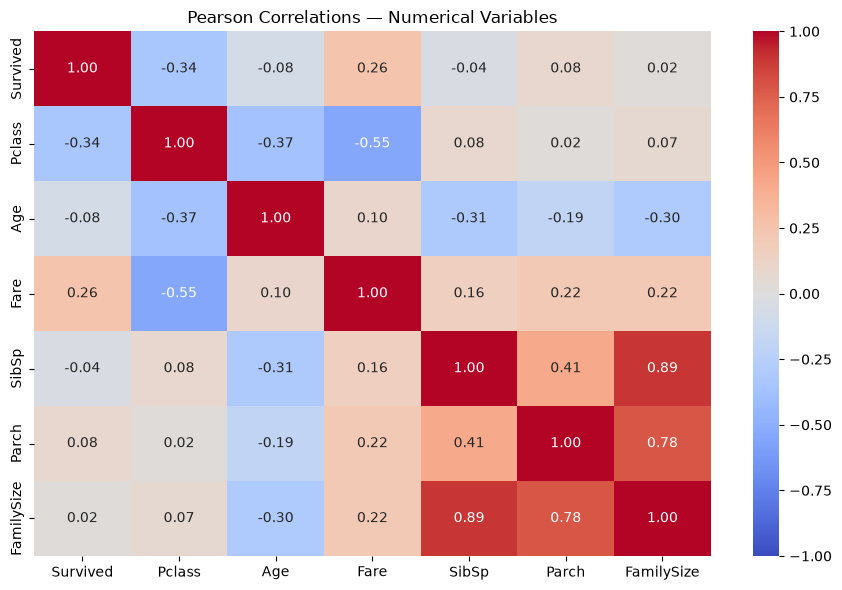

In [89]:
plt.figure(figsize=(9, 6))
sns.heatmap(correlation_matrix, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.title("Pearson Correlations — Numerical Variables")
plt.tight_layout()
plt.show()

## Q28) Three Clearest Associations with Survival

**Objective:** Summarize large, interpretable contrasts without claiming independent effects.

In [90]:
print("Sex:")
print(survival_by_sex.to_string(index=False))
print("\nPassenger class:")
print(survival_by_class.to_string(index=False))
print("\nCabin information:")
print(survival_by_cabin.to_string(index=False))

Sex:
   Sex  Passengers  Survivors  Survival_Pct
female         314        233     74.203822
  male         577        109     18.890815

Passenger class:
 Pclass  Passengers  Survivors  Survival_Pct
      1         216        136     62.962963
      2         184         87     47.282609
      3         491        119     24.236253

Cabin information:
Cabin_Info  Passengers  Survivors  Survival_Pct
 Available         204        136     66.666667
   Missing         687        206     29.985444


### Interpretation

**Sex, passenger class and cabin-information availability** show three clear descriptive contrasts. Sex and class remain distinct patterns in Q12. Cabin availability overlaps with class, so these are not three proven independent drivers or a formal causal ranking. Age, family size and fare remain relevant findings.

## Q29) Possible Confounding

**Objective:** Use class as a concrete example of overlapping relationships.

In [91]:
print("Survival within class and fare group:")
print(survival_by_class_fare.to_string(index=False))
print("\nClass composition by embarkation port (%):")
print(port_class_mix)

Survival within class and fare group:
 Pclass  FareGroup  Passengers  Survivors  Survival_Pct
      1  Q1 Lowest           6          0      0.000000
      1         Q3          51         27     52.941176
      1 Q4 Highest         159        109     68.553459
      2  Q1 Lowest           6          0      0.000000
      2         Q2          86         33     38.372093
      2         Q3          70         42     60.000000
      2 Q4 Highest          22         12     54.545455
      3  Q1 Lowest         211         44     20.853081
      3         Q2         138         35     25.362319
      3         Q3         101         32     31.683168
      3 Q4 Highest          41          8     19.512195

Class composition by embarkation port (%):
Pclass             1          2          3
Embarked                                  
C          50.595238  10.119048  39.285714
Q           2.597403   3.896104  93.506494
S          19.720497  25.465839  54.813665
Unknown   100.000000   0.000000

### Interpretation

Passenger class is associated with both Fare and survival, so it can confound the fare comparison. Cherbourg also has a larger first-class share than Southampton, influencing aggregate port rates. Stratifying by class helps inspect this explanation but does not prove causation or remove all confounding.

## Q30) Dataset Limitations

**Objective:** Review missingness and limitations affecting the conclusions.

In [92]:
limitations_summary = pd.Series({
    "Passenger records": len(df_raw),
    "Missing ages": df_raw["Age"].isna().sum(),
    "Missing age percentage": df_raw["Age"].isna().mean() * 100,
    "Missing cabins": df_raw["Cabin"].isna().sum(),
    "Missing cabin percentage": df_raw["Cabin"].isna().mean() * 100,
    "Missing ports": df_raw["Embarked"].isna().sum(),
    "Distinct tickets in sample": df_raw["Ticket"].nunique()
})

limitations_summary

Passenger records             891.000000
Missing ages                  177.000000
Missing age percentage         19.865320
Missing cabins                687.000000
Missing cabin percentage       77.104377
Missing ports                   2.000000
Distinct tickets in sample    681.000000
dtype: float64

### Interpretation

This observational sample does not cover every person aboard. Missing ages and cabins may be systematic, rare groups have unstable rates, passengers can share family/ticket circumstances, and exact locations or rescue access are unavailable. Avoid causal conclusions, guaranteed individual predictions, or assuming the sample represents the full ship without checking. Many exploratory comparisons are not formal hypothesis tests.

# 7) Key Findings

| Finding | Evidence in this sample | Main qualification |
|---|---|---|
| Most passengers did not survive | 342/891 survived: 38.38% | Sample, not the entire ship population |
| Sex has a large association | Females 74.20%; males 18.89% | Describe recorded groups, not causal certainty |
| Survival differs across classes | First 62.96%; second 47.28%; third 24.24% | Class overlaps with fare and cabin documentation |
| Sex and class interact descriptively | First-class females 96.81%; third-class males 13.54% | Both factors remain relevant when considered together |
| Children have higher observed survival | Under 16: 59.04%; known-age adults: 38.19% | 177 unknown ages; threshold-dependent |
| Family/travel groups differ | With recorded family 50.56%; alone 30.35% | FamilySize does not include every companion |
| Fare is associated with survival | Highest quartile 58.11%; lowest 19.73% | High fares are concentrated in first class |
| Cabin availability is associated with survival | Available 66.67%; missing 29.99% | 77.10% missing; documentation overlaps with class |

The clearest findings come from combining several summaries rather than treating a chart or correlation as a complete explanation.

# 8) Conclusion

This notebook examined patterns associated with survival among 891 Titanic passengers. Overall survival was 38.38%. Recorded sex and passenger class showed large differences: female survival was 74.20% compared with 18.89% for males, and first-class survival was 62.96% compared with 24.24% in third class. Females had higher survival within every class. Children and passengers with recorded family also showed higher rates, while fare, cabin documentation and embarkation patterns overlapped with class composition.

The findings describe associations rather than causes. Missing age for 19.87% of passengers, missing cabin for 77.10%, small subgroups, shared family/ticket circumstances and unmeasured rescue conditions limit interpretation. Survival varied sharply across passenger groups, but no single variable completely explains the observed outcomes.

## 8.1) Export the Prepared Dataset

**Objective:** Save the analysis-ready table while keeping the source CSV untouched.

In [93]:
df_clean.to_csv("titanic_prepared.csv", index=False)
print("Saved: titanic_prepared.csv")

Saved: titanic_prepared.csv


In [94]:
%whos

Variable                  Type         Data/Info
------------------------------------------------
age_bins                  list         n=6
age_by_class              DataFrame    Shape: (3, 3)
age_by_outcome            DataFrame    Shape: (2, 5)
age_group_ranked          DataFrame    Shape: (5, 4)
age_labels                list         n=5
categorical_cols          list         n=4
class_map                 dict         n=3
col                       str          Embarked
correlation_columns       list         n=7
correlation_matrix        DataFrame    Shape: (7, 7)
df                        DataFrame    Shape: (891, 12)
df_age                    DataFrame    Shape: (714, 18)
df_clean                  DataFrame    Shape: (891, 23)
df_raw                    DataFrame    Shape: (891, 12)
eda_columns               list         n=6
fare_by_class             DataFrame    Shape: (3, 5)
fare_by_outcome           DataFrame    Shape: (2, 5)
fare_labels               list         n=4
flagged    